<div dir="rtl">

# تمرین ۱ — طراحی و تحلیل شبکه عصبی کانولوشن (CNN) روی دیتاست BCCD

**هدف:** طبقه‌بندی تصاویر گلبول‌های سفید خون در ۴ کلاس
(`EOSINOPHIL`, `LYMPHOCYTE`, `MONOCYTE`, `NEUTROPHIL`) با یک شبکه کانولوشنی که **از صفر** پیاده‌سازی شده است (بدون Transfer Learning).

ساختار نوت‌بوک مطابق صورت تمرین:

1. **بخش اول:** بارگذاری داده، تقسیم ۷۰/۱۵/۱۵، تغییر اندازه به ۶۴×۶۴، نرمال‌سازی به بازه [0, 1] و افزایش داده
2. **بخش دوم:** طراحی معماری CNN (۴ بلوک Conv → BN → ReLU → MaxPool و Dropout در بخش FC)
3. **بخش سوم:** آموزش با Adam (lr=0.001)، Batch=64، حداکثر ۱۵ اپوک، Checkpoint و Early Stopping
4. **بخش چهارم:** نمودارهای Loss/Accuracy، ماتریس درهم‌ریختگی، Precision/Recall/F1 و مصورسازی نقشه‌های ویژگی

همه کدها روی CPU قابل اجرا هستند.
</div>

<div dir="rtl">

## ۰. کتابخانه‌ها و تنظیمات کلی
</div>

In [1]:
import os, time, random, copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# ---------------- Global configuration ----------------
DATA_ROOT   = "dataset2-master/images"           # folder that contains TRAIN/ and TEST/
CLASSES     = ["EOSINOPHIL", "LYMPHOCYTE", "MONOCYTE", "NEUTROPHIL"]
IMG_SIZE    = 64          # images are resized to exactly 64x64 (CPU friendly)
BATCH_SIZE  = 64
EPOCHS      = 15          # maximum number of epochs
LR          = 1e-3        # Adam learning rate
WEIGHT_DECAY = 1e-4       # small L2 regularisation inside Adam
PATIENCE    = 5           # early-stopping patience (epochs without val improvement)
SEED        = 42
# "group"  : split by ORIGINAL image id -> no leakage between splits (recommended, see section 1.2)
# "random" : plain stratified random split over all images
SPLIT_MODE  = "group"
OUT_DIR     = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed):
    # make results reproducible
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count())
print("PyTorch:", torch.__version__, "| device:", device, "| CPU threads:", torch.get_num_threads())

PyTorch: 2.14.1+cu130 | device: cpu | CPU threads: 4


<div dir="rtl">

## بخش اول: بارگذاری و افزایش داده (Data Pipeline & Augmentation)

### ۱.۱ خواندن مسیر فایل‌ها

پوشه `dataset2-master/images` شامل `TRAIN` و `TEST` (و یک پوشه کوچک `TEST_SIMPLE` که همان تصاویر اصلیِ TEST است و استفاده نمی‌شود) است.
تمام تصاویر `TRAIN` و `TEST` را با هم جمع می‌کنیم و سپس خودمان آن‌ها را به نسبت ۷۰/۱۵/۱۵ تقسیم می‌کنیم.
</div>

In [2]:
records = []
for folder in ["TRAIN", "TEST"]:
    for label, cls in enumerate(CLASSES):
        cls_dir = os.path.join(DATA_ROOT, folder, cls)
        for fname in sorted(os.listdir(cls_dir)):
            if not fname.lower().endswith((".jpeg", ".jpg", ".png")):
                continue
            # file names look like "_<originalId>_<augId>.jpeg"
            orig_id = fname.split("_")[1]
            records.append({
                "path": os.path.join(cls_dir, fname),
                "label": label,
                "cls": cls,
                # every original microscope image (and all its augmented copies) gets one group id
                "group": f"{folder}/{cls}/{orig_id}",
            })

df = pd.DataFrame(records)
print("Total images:", len(df))
print("Number of distinct original images (groups):", df["group"].nunique())
display(df.groupby("cls").agg(images=("path", "size"), original_images=("group", "nunique")))

Total images: 12444
Number of distinct original images (groups): 348


,images,original_images
cls,,
EOSINOPHIL,3120,88
LYMPHOCYTE,3103,33
MONOCYTE,3098,20
NEUTROPHIL,3123,207


<div dir="rtl">

### ۱.۲ تقسیم داده به Train (۷۰٪) / Validation (۱۵٪) / Test (۱۵٪)

**نکته مهم (نشت داده):** تصاویر این نسخه از دیتاست از قبل Augment شده‌اند؛ یعنی از هر تصویر میکروسکوپی اصلی
ده‌ها نسخه‌ی چرخیده/قرینه ساخته شده است (عدد اول نام فایل، شناسه‌ی تصویر اصلی است).
اگر تقسیم کاملاً تصادفی باشد، نسخه‌های تقریباً یکسان از یک تصویر هم در Train و هم در Test قرار می‌گیرند و دقت تست به‌صورت
غیرواقعی بالا می‌رود. بنابراین در حالت پیش‌فرض (`SPLIT_MODE="group"`) تقسیم بر اساس **تصویر اصلی** و به‌صورت طبقه‌بندی‌شده (stratified)
انجام می‌شود تا هیچ تصویر اصلی در دو مجموعه مشترک نباشد، و در عین حال نسبت تعداد تصاویر هر کلاس ≈ ۷۰/۱۵/۱۵ بماند.
(با `SPLIT_MODE="random"` می‌توان تقسیم تصادفی ساده را هم امتحان کرد.)
</div>

In [3]:
def group_stratified_split(df, ratios=(0.70, 0.15, 0.15), seed=SEED):
    # For every class: shuffle its groups (original images) and fill val, test, then train
    # until each split reaches its target number of images.
    rng = np.random.default_rng(seed)
    split = pd.Series(index=df.index, dtype=object)
    for cls, cdf in df.groupby("cls"):
        groups = list(cdf["group"].unique())
        rng.shuffle(groups)
        sizes = cdf.groupby("group").size()
        n_total = len(cdf)
        target = {"val": ratios[1] * n_total, "test": ratios[2] * n_total}
        filled = {"val": 0, "test": 0}
        for g in groups:
            # put the group in the split that is furthest from its target (train takes the rest)
            name = max(target, key=lambda k: target[k] - filled[k])
            if filled[name] + sizes[g] / 2 <= target[name]:
                filled[name] += sizes[g]
            else:
                name = "train"
            split[cdf.index[cdf["group"] == g]] = name
    return split

def random_stratified_split(df, ratios=(0.70, 0.15, 0.15), seed=SEED):
    from sklearn.model_selection import train_test_split
    idx_train, idx_tmp = train_test_split(df.index, test_size=ratios[1] + ratios[2],
                                          stratify=df["label"], random_state=seed)
    idx_val, idx_test = train_test_split(idx_tmp, test_size=ratios[2] / (ratios[1] + ratios[2]),
                                         stratify=df.loc[idx_tmp, "label"], random_state=seed)
    split = pd.Series(index=df.index, dtype=object)
    split[idx_train], split[idx_val], split[idx_test] = "train", "val", "test"
    return split

df["split"] = group_stratified_split(df) if SPLIT_MODE == "group" else random_stratified_split(df)

# sanity check: no original image appears in two different splits
assert SPLIT_MODE != "group" or df.groupby("group")["split"].nunique().max() == 1

summary = pd.crosstab(df["cls"], df["split"])[["train", "val", "test"]]
summary.loc["TOTAL"] = summary.sum()
summary["train %"] = (100 * summary["train"] / summary[["train", "val", "test"]].sum(axis=1)).round(1)
display(summary)

split,train,val,test,train %
cls,,,,
EOSINOPHIL,2193,467,460,70.3
LYMPHOCYTE,2182,457,464,70.3
MONOCYTE,2168,465,465,70.0
NEUTROPHIL,2196,463,464,70.3
TOTAL,8739,1852,1853,70.2


<div dir="rtl">

### ۱.۳ تغییر اندازه به ۶۴×۶۴ و بارگذاری در حافظه

ابعاد اصلی تصاویر ۳۲۰×۲۴۰ است. همه تصاویر **دقیقاً به ۶۴×۶۴** تغییر اندازه داده می‌شوند و یک‌بار به صورت `uint8` در RAM نگه داشته می‌شوند
(حدود ۱۵۰ مگابایت) تا آموزش روی CPU سریع باشد. نرمال‌سازی به بازه **[−1, 1]** در زمان ساخت هر batch انجام می‌شود:
ابتدا `ToDtype(scale=True)` مقادیر را به [0, 1] می‌برد (تقسیم بر ۲۵۵) و سپس `Normalize(mean=0.5, std=0.5)` آن‌ها را به [−1, 1] منتقل می‌کند
(ورودی صفر-مرکز، آموزش را پایدارتر می‌کند؛ بخش ۳.۱ را ببینید).
</div>

In [4]:
def load_resized(path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

t0 = time.time()
all_images = np.stack([load_resized(p) for p in df["path"]])            # (N, 64, 64, 3) uint8
all_images = torch.from_numpy(all_images).permute(0, 3, 1, 2).contiguous()  # (N, 3, 64, 64)
all_labels = torch.tensor(df["label"].values, dtype=torch.long)
print(f"Loaded {len(all_images)} images in {time.time() - t0:.1f}s -> tensor {tuple(all_images.shape)}, dtype={all_images.dtype}")

orig = Image.open(df["path"].iloc[0])
print("Original size:", orig.size, "-> new size:", tuple(all_images.shape[2:]))

Loaded 12444 images in 11.7s -> tensor (12444, 3, 64, 64), dtype=torch.uint8
Original size: (320, 240) -> new size: (64, 64)


<div dir="rtl">

### ۱.۴ تعریف Augmentation و Dataset

افزایش داده **فقط روی داده آموزش** اعمال می‌شود:
- `RandomRotation(±20°)` — چرخش تصادفی
- `RandomHorizontalFlip(p=0.5)` — قرینه‌سازی افقی (به‌علاوه `RandomVerticalFlip`؛ سلول خونی جهت خاصی ندارد)
- `RandomResizedCrop(scale=0.8–1.0)` و `RandomAffine(translate=5%)` — برش/تغییر مقیاس و جابه‌جایی کوچک
- `ColorJitter` ملایم — شبیه‌سازی تفاوت رنگ‌آمیزی و نور میکروسکوپ بین نمونه‌ها (اضافه بر خواسته تمرین)

داده‌های Validation و Test فقط به [−1, 1] نرمال می‌شوند.
</div>

In [5]:
train_tf = T.Compose([
    T.RandomRotation(degrees=20),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomResizedCrop(size=IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
    T.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03),
    T.ToDtype(torch.float32, scale=True),     # uint8 [0,255] -> float [0,1]
    T.Normalize([0.5] * 3, [0.5] * 3),        # [0,1] -> [-1,1]
])
eval_tf = T.Compose([                         # only normalisation for val / test
    T.ToDtype(torch.float32, scale=True),
    T.Normalize([0.5] * 3, [0.5] * 3),
])

def to_img(x):
    # [-1,1] float tensor (C,H,W) -> [0,1] (H,W,C) for plotting
    return (x * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)

class BloodCellDataset(Dataset):
    # Wraps the pre-loaded uint8 tensors and applies a transform on the fly
    def __init__(self, indices, transform):
        self.indices = np.asarray(indices)
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        return self.transform(all_images[j]), all_labels[j]

idx = {s: np.where(df["split"].values == s)[0] for s in ["train", "val", "test"]}
train_ds = BloodCellDataset(idx["train"], train_tf)
val_ds   = BloodCellDataset(idx["val"],   eval_tf)
test_ds  = BloodCellDataset(idx["test"],  eval_tf)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

x, y = next(iter(train_loader))
print("Batch:", tuple(x.shape), "| min=%.3f max=%.3f" % (x.min(), x.max()))
print("train/val/test sizes:", len(train_ds), len(val_ds), len(test_ds))

Batch: (64, 3, 64, 64) | min=-1.000 max=1.000
train/val/test sizes: 8739 1852 1853


<div dir="rtl">

### ۱.۵ نمایش نمونه‌ها و اثر Augmentation
</div>

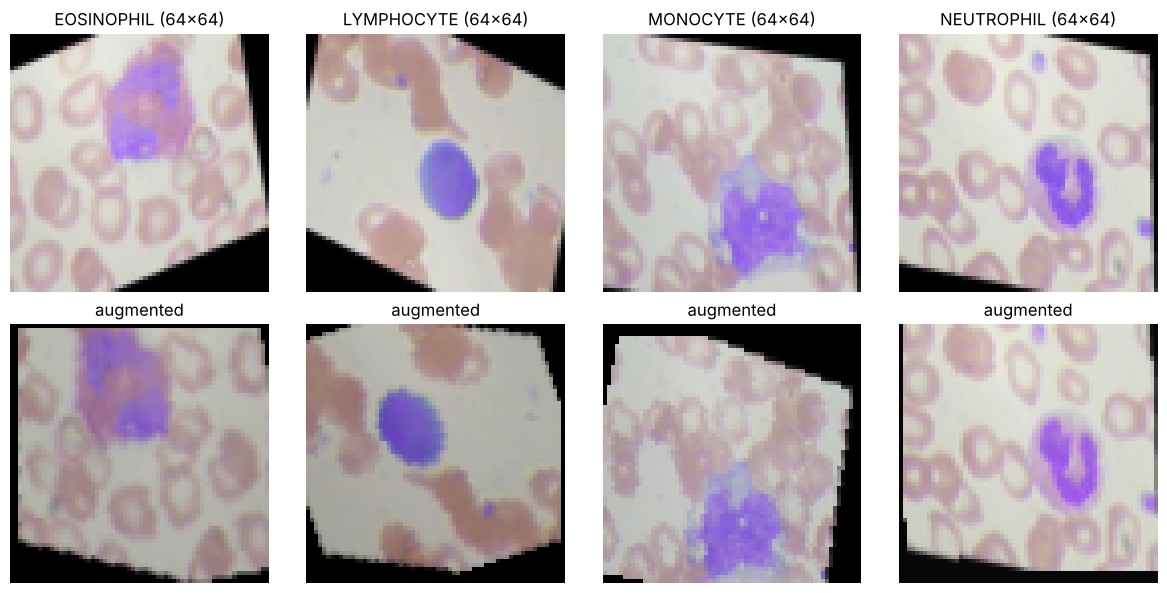

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c, cls in enumerate(CLASSES):
    j = idx["train"][np.where(all_labels[idx["train"]] == c)[0][0]]
    axes[0, c].imshow(all_images[j].permute(1, 2, 0)); axes[0, c].set_title(f"{cls} (64x64)")
    axes[1, c].imshow(to_img(train_tf(all_images[j]))); axes[1, c].set_title("augmented")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/samples_augmentation.png", dpi=120); plt.show()

<div dir="rtl">

## بخش دوم: طراحی معماری شبکه کانولوشن

شبکه سفارشی `BloodCellCNN` شامل **۴ بلوک کانولوشن متوالی** است؛ هر بلوک:
`Conv2d → BatchNorm2d → ReLU → MaxPool2d(2)`

- بلوک اول فیلتر ۵×۵ دارد (میدان دید بزرگ‌تر برای یادگیری لبه‌ها/بافت‌های اولیه) و بقیه ۳×۳ هستند.
- تعداد کانال‌ها: 3 → 32 → 64 → 128 → 256 و ابعاد مکانی: 64 → 32 → 16 → 8 → 4
- بخش Fully Connected: `GlobalAvgPool(256) → Dropout(0.5) → Linear(128) → ReLU → Dropout(0.3) → Linear(4)`
  (میانگین‌گیری سراسری به‌جای Flatten کردن 4096 ویژگی، تعداد پارامترهای FC را از حدود ۱ میلیون به ۳۳ هزار کاهش می‌دهد و بیش‌برازش را کم می‌کند)
- لایه خروجی ۴ نورون (logits) دارد و تابع زیان `CrossEntropyLoss` است (Softmax درون همین تابع زیان اعمال می‌شود).
</div>

In [7]:
class ConvBlock(nn.Module):
    # Conv2D -> BatchNorm -> ReLU -> MaxPool(2x2)
    def __init__(self, in_ch, out_ch, k=3):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=k, padding=k // 2, bias=False)  # BN has its own bias
        self.bn   = nn.BatchNorm2d(out_ch)
        self.act  = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(2)
    def forward(self, x):
        return self.pool(self.act(self.bn(self.conv(x))))

class BloodCellCNN(nn.Module):
    def __init__(self, num_classes=4, p_drop=0.5):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3,   32, k=5),   # 64x64 -> 32x32
            ConvBlock(32,  64),        # 32x32 -> 16x16
            ConvBlock(64,  128),       # 16x16 -> 8x8
            ConvBlock(128, 256),       # 8x8   -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),            # global average pooling: 256x4x4 -> 256x1x1
            nn.Flatten(),                       # -> 256
            nn.Dropout(p_drop),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),        # logits for the 4 classes
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = BloodCellCNN(num_classes=len(CLASSES)).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

BloodCellCNN(
  (features): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): ReLU(inplace=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ConvBlock(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (act): ReLU(inplace=True)
      (pool): MaxPool2d(kern

<div dir="rtl">

### جدول مشخصات معماری (سایز فیلتر، تعداد کانال، ابعاد خروجی هر لایه)

این جدول با forward hook و یک ورودی نمونه ۶۴×۶۴ ساخته می‌شود تا ابعاد خروجی دقیقاً همان چیزی باشد که شبکه تولید می‌کند.
</div>

In [8]:
def architecture_table(model, input_size=(1, 3, IMG_SIZE, IMG_SIZE)):
    rows, hooks = [], []
    def hook(name):
        def fn(m, inp, out):
            kernel = getattr(m, "kernel_size", "-")
            kernel = f"{kernel[0]}x{kernel[1]}" if isinstance(kernel, tuple) else (f"{kernel}x{kernel}" if kernel != "-" else "-")
            rows.append({
                "Layer": name,
                "Type": m.__class__.__name__,
                "Kernel / Stride": f"{kernel} / {m.stride if not isinstance(m.stride, tuple) else m.stride[0]}" if hasattr(m, "stride") else "-",
                "In ch": m.in_channels if hasattr(m, "in_channels") else (m.in_features if hasattr(m, "in_features") else "-"),
                "Out ch": m.out_channels if hasattr(m, "out_channels") else (m.out_features if hasattr(m, "out_features") else "-"),
                "Output shape": "x".join(map(str, out.shape[1:])),
                "Params": sum(p.numel() for p in m.parameters()),
            })
        return fn
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:      # leaf layers only
            hooks.append(m.register_forward_hook(hook(name)))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=device))
    for h in hooks: h.remove()
    return pd.DataFrame(rows)

arch_df = architecture_table(model)
arch_df.to_csv(f"{OUT_DIR}/architecture_table.csv", index=False)
pd.set_option("display.max_rows", 50)
display(arch_df)
print("Total params:", arch_df["Params"].sum())

,Layer,Type,Kernel / Stride,In ch,Out ch,Output shape,Params
0,features.0.conv,Conv2d,5x5 / 1,3,32,32x64x64,2400
1,features.0.bn,BatchNorm2d,-,-,-,32x64x64,64
2,features.0.act,ReLU,-,-,-,32x64x64,0
3,features.0.pool,MaxPool2d,2x2 / 2,-,-,32x32x32,0
4,features.1.conv,Conv2d,3x3 / 1,32,64,64x32x32,18432
5,features.1.bn,BatchNorm2d,-,-,-,64x32x32,128
6,features.1.act,ReLU,-,-,-,64x32x32,0
7,features.1.pool,MaxPool2d,2x2 / 2,-,-,64x16x16,0
8,features.2.conv,Conv2d,3x3 / 1,64,128,128x16x16,73728
9,features.2.bn,BatchNorm2d,-,-,-,128x16x16,256


Total params: 423844


<div dir="rtl">

## بخش سوم: آموزش و تنظیم فراپارامترها

- بهینه‌ساز: **Adam** با `lr = 0.001` و `weight_decay = 1e-4`
- زمان‌بندی نرخ یادگیری: **CosineAnnealing** (کاهش نرم lr از 0.001 تا نزدیک صفر در طول ۱۵ اپوک)
- اندازه دسته: **64**، حداکثر **15 اپوک**
- **Model Checkpoint:** وزن‌های مدلی که کمترین Loss روی Validation را دارد در `best_model.pt` ذخیره می‌شود.
- **Early Stopping:** اگر Loss اعتبارسنجی به مدت ۵ اپوک بهتر نشود، آموزش متوقف می‌شود.
</div>

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(model, loader, train=False):
    # One pass over a loader; returns (mean loss, accuracy)
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, best_epoch, wait = float("inf"), 0, 0
CKPT = "best_model.pt"

t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = run_epoch(model, train_loader, train=True)
    va_loss, va_acc = run_epoch(model, val_loader, train=False)
    scheduler.step()
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)

    msg = ""
    if va_loss < best_val_loss:              # ---- model checkpoint ----
        best_val_loss, best_epoch, wait = va_loss, epoch, 0
        torch.save(model.state_dict(), CKPT)
        msg = "  <-- best, saved"
    else:
        wait += 1
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - t0:.1f}s{msg}")
    if wait >= PATIENCE:                     # ---- early stopping ----
        print(f"Early stopping at epoch {epoch} (no val improvement for {PATIENCE} epochs)")
        break

print(f"\nTraining time: {(time.time() - t_start) / 60:.1f} min | best epoch: {best_epoch} "
      f"(val loss {best_val_loss:.4f}, val acc {history['val_acc'][best_epoch - 1]:.4f})")
pd.DataFrame(history, index=pd.RangeIndex(1, len(history["train_loss"]) + 1, name="epoch")).to_csv(f"{OUT_DIR}/history.csv")

Epoch 01/15 | train loss 1.1511 acc 0.4586 | val loss 0.8418 acc 0.6139 | 40.7s  <-- best, saved


Epoch 02/15 | train loss 0.6630 acc 0.7134 | val loss 0.7969 acc 0.6404 | 41.1s  <-- best, saved


Epoch 03/15 | train loss 0.4991 acc 0.7874 | val loss 0.6626 acc 0.7003 | 41.2s  <-- best, saved


Epoch 04/15 | train loss 0.4087 acc 0.8300 | val loss 2.5042 acc 0.4428 | 39.8s


Epoch 05/15 | train loss 0.3522 acc 0.8547 | val loss 0.5857 acc 0.7921 | 43.5s  <-- best, saved


...

Epoch 11/15 | train loss 0.1837 acc 0.9250 | val loss 0.1358 acc 0.9530 | 39.0s  <-- best, saved


Epoch 12/15 | train loss 0.1618 acc 0.9357 | val loss 0.0913 acc 0.9644 | 40.0s  <-- best, saved


Epoch 13/15 | train loss 0.1494 acc 0.9416 | val loss 0.0987 acc 0.9617 | 39.4s


Epoch 14/15 | train loss 0.1333 acc 0.9476 | val loss 0.0767 acc 0.9708 | 38.7s  <-- best, saved


Epoch 15/15 | train loss 0.1339 acc 0.9472 | val loss 0.0737 acc 0.9730 | 40.4s  <-- best, saved

Training time: 10.1 min | best epoch: 15 (val loss 0.0737, val acc 0.9730)


<div dir="rtl">

### ۳.۱ تنظیم فراپارامترها (روند رسیدن به تنظیمات نهایی)

| نسخه | تنظیمات | بهترین Val Acc | Test Acc | مشاهده |
|---|---|---|---|---|
| ۱ (پایه) | ورودی [0,1]، Flatten→FC(256)، Adam بدون زمان‌بند، Augment پایه | 0.766 | 0.751 | Loss اعتبارسنجی بسیار ناپایدار (تا 13.5) و توقف زودهنگام در اپوک ۱۰ |
| ۲ | + ورودی [−1,1]، ColorJitter و VerticalFlip، weight decay، Cosine LR | 0.933 | 0.935 | آموزش پایدار شد |
| ۳ (نهایی) | + Global Average Pooling به‌جای Flatten (FC کوچک‌تر) | 0.973 | 0.980 | کمترین Loss اعتبارسنجی؛ بهترین مدل در اپوک ۱۵ |

علت اصلی ناپایداری نسخه ۱: هر مجموعه از تصاویر اصلی متفاوتی است (تفاوت رنگ‌آمیزی/نور)، و لایه FC بزرگ (۱ میلیون پارامتر) روی جزئیات
تصاویر آموزش بیش‌برازش می‌کرد. ColorJitter این تفاوت را شبیه‌سازی می‌کند و GAP ظرفیت بخش FC را کم می‌کند.
(اعداد نسخه‌های ۱ و ۲ از اجراهای جداگانه با همین کد گزارش شده‌اند.)
</div>

<div dir="rtl">

## بخش چهارم: ارزیابی و مصورسازی

### ۴.۱ نمودار هم‌زمان Loss و Accuracy برای Train و Validation
خط‌چین عمودی اپوکی را نشان می‌دهد که بهترین مدل در آن ذخیره شده است.
</div>

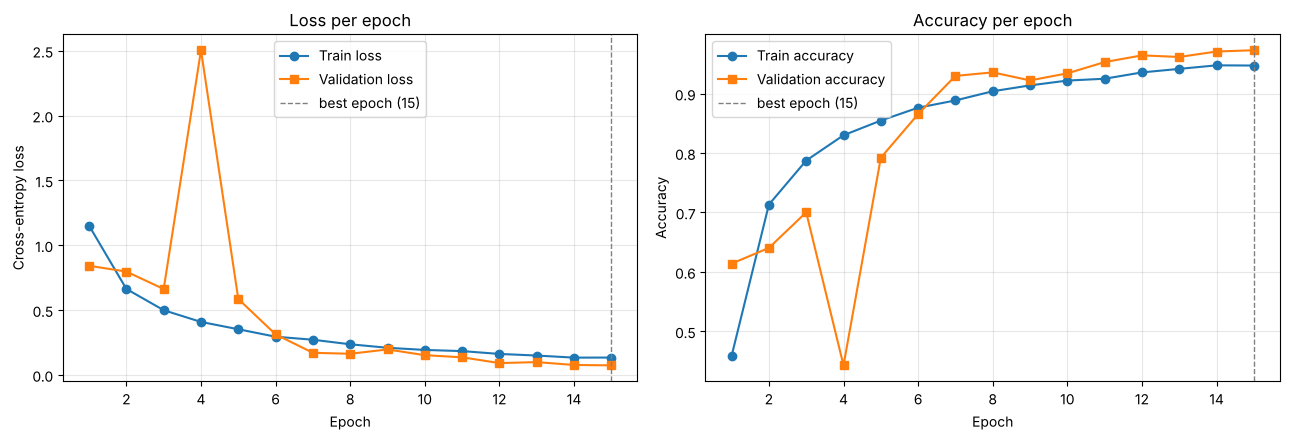

In [10]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(epochs, history["train_loss"], "o-", label="Train loss")
ax[0].plot(epochs, history["val_loss"],   "s-", label="Validation loss")
ax[0].set_title("Loss per epoch"); ax[0].set_ylabel("Cross-entropy loss")
ax[1].plot(epochs, history["train_acc"], "o-", label="Train accuracy")
ax[1].plot(epochs, history["val_acc"],   "s-", label="Validation accuracy")
ax[1].set_title("Accuracy per epoch"); ax[1].set_ylabel("Accuracy")
for a in ax:
    a.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"best epoch ({best_epoch})")
    a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

<div dir="rtl">

### ۴.۲ ارزیابی روی داده Test با بهترین مدل: ماتریس درهم‌ریختگی و Precision / Recall / F1
</div>

Test accuracy: 0.9800

              precision    recall  f1-score   support

  EOSINOPHIL     0.9670    0.9543    0.9606       460
  LYMPHOCYTE     0.9978    1.0000    0.9989       464
    MONOCYTE     1.0000    0.9978    0.9989       465
  NEUTROPHIL     0.9553    0.9677    0.9615       464

    accuracy                         0.9800      1853
   macro avg     0.9800    0.9800    0.9800      1853
weighted avg     0.9801    0.9800    0.9800      1853



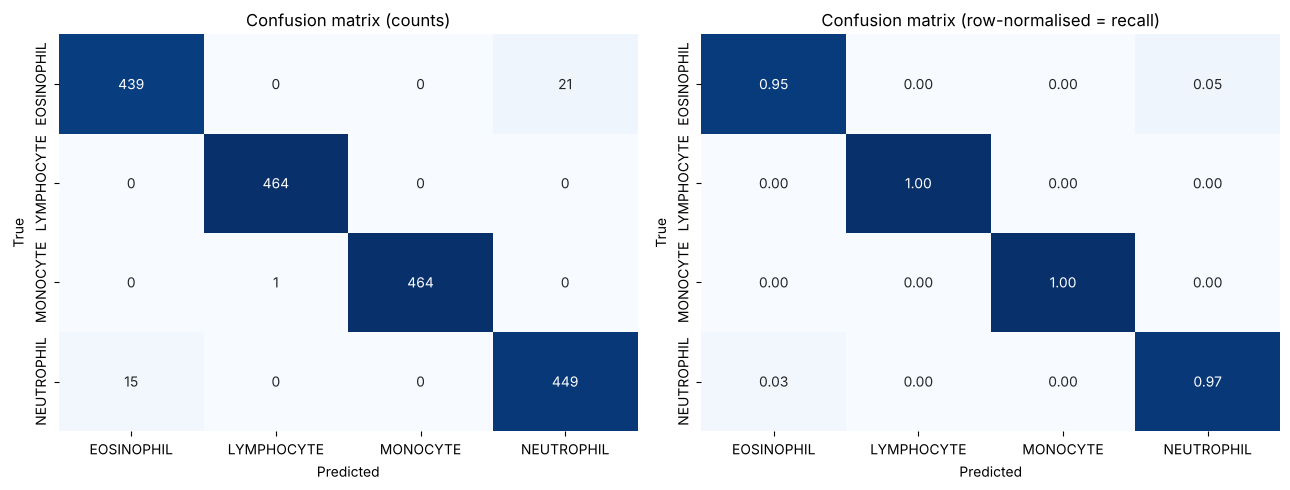

In [11]:
model.load_state_dict(torch.load(CKPT, map_location=device))   # restore best checkpoint
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred.append(model(x.to(device)).argmax(1).cpu())
        y_true.append(y)
y_true, y_pred = torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.4f}\n")
report = classification_report(y_true, y_pred, target_names=CLASSES, digits=4)
print(report)
pd.DataFrame(classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)).T.round(4) \
  .to_csv(f"{OUT_DIR}/classification_report.csv")

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False, vmin=0, vmax=1)
ax[1].set_title("Confusion matrix (row-normalised = recall)")
for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

<div dir="rtl">

### ۴.۳ مصورسازی فیلترها و نقشه‌های ویژگی (Feature Maps)

یک تصویر از داده Test انتخاب می‌شود و با forward hook خروجی **اولین لایه کانولوشن** (بلوک ۱ پس از BN+ReLU، 32 کانال 64×64)
و **آخرین لایه کانولوشن** (بلوک ۴ پس از BN+ReLU، 256 کانال 8×8) استخراج و نمایش داده می‌شود.
همچنین وزن‌های ۵×۵ فیلترهای لایه اول هم به‌صورت تصویر RGB نمایش داده می‌شوند.
</div>

True: EOSINOPHIL | predicted: EOSINOPHIL (p=1.000)
first conv activations: (32, 64, 64) | last conv activations: (256, 8, 8)


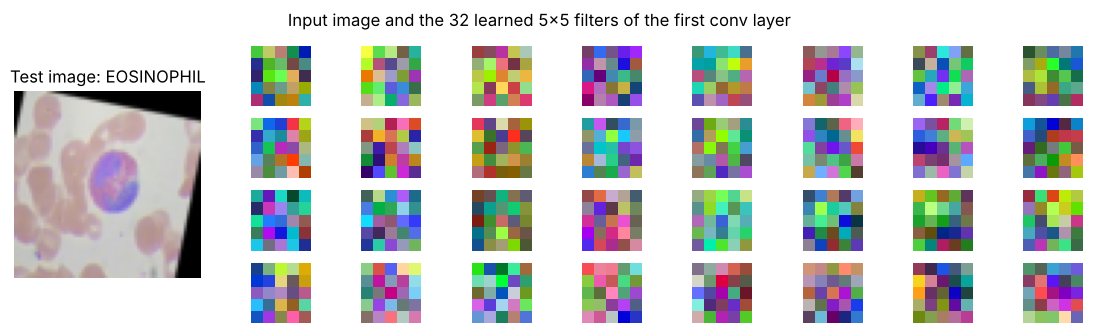

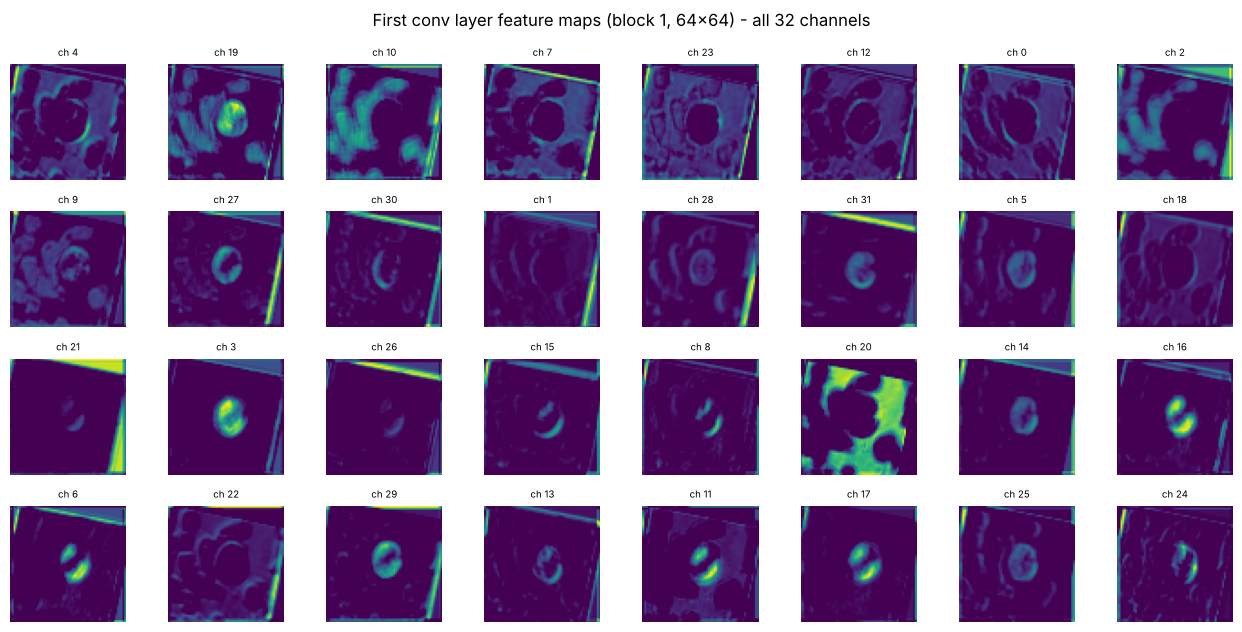

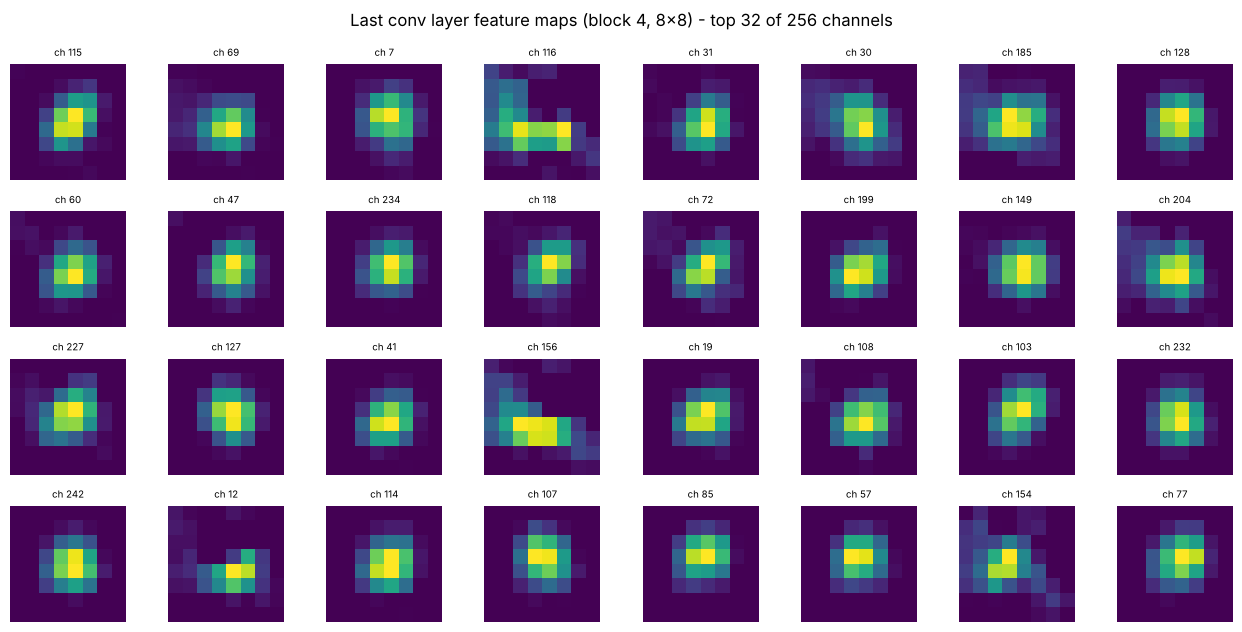

In [12]:
# pick a correctly classified test image (first EOSINOPHIL in the test split)
sample_pos = int(np.where((y_true == 0) & (y_pred == 0))[0][0])
sample_img, sample_label = test_ds[sample_pos]

activations = {}
def save_act(name):
    def fn(m, inp, out): activations[name] = out.detach().cpu()[0]
    return fn
h1 = model.features[0].act.register_forward_hook(save_act("first_conv"))   # conv1 -> BN -> ReLU
h2 = model.features[-1].act.register_forward_hook(save_act("last_conv"))   # conv4 -> BN -> ReLU
with torch.no_grad():
    probs = torch.softmax(model(sample_img.unsqueeze(0).to(device)), 1)[0].cpu()
h1.remove(); h2.remove()
print("True:", CLASSES[sample_label], "| predicted:", CLASSES[probs.argmax()], f"(p={probs.max():.3f})")
print("first conv activations:", tuple(activations["first_conv"].shape),
      "| last conv activations:", tuple(activations["last_conv"].shape))

# --- input image + learned first-layer filters (5x5x3 kernels shown as RGB) ---
w = model.features[0].conv.weight.detach().cpu()               # (32, 3, 5, 5)
w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True))
fig = plt.figure(figsize=(14, 3.6))
ax0 = fig.add_subplot(1, 5, 1); ax0.imshow(to_img(sample_img)); ax0.set_title(f"Test image: {CLASSES[sample_label]}"); ax0.axis("off")
for i in range(32):
    a = fig.add_subplot(4, 10, (i // 8) * 10 + 3 + i % 8)
    a.imshow(w[i].permute(1, 2, 0)); a.axis("off")
fig.suptitle("Input image and the 32 learned 5x5 filters of the first conv layer")
plt.savefig(f"{OUT_DIR}/first_layer_filters.png", dpi=150, bbox_inches="tight"); plt.show()

def plot_maps(maps, title, fname, n=32, ncols=8):
    # show the n channels with the highest mean activation
    order = maps.mean(dim=(1, 2)).argsort(descending=True)[:n]
    fig, axes = plt.subplots(n // ncols, ncols, figsize=(ncols * 1.6, n // ncols * 1.6))
    for a, ch in zip(axes.ravel(), order):
        a.imshow(maps[ch], cmap="viridis"); a.set_title(f"ch {ch.item()}", fontsize=7); a.axis("off")
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

plot_maps(activations["first_conv"], "First conv layer feature maps (block 1, 64x64) - all 32 channels", "feature_maps_first_conv.png")
plot_maps(activations["last_conv"],  "Last conv layer feature maps (block 4, 8x8) - top 32 of 256 channels", "feature_maps_last_conv.png")

<div dir="rtl">

### تحلیل نقشه‌های ویژگی

- **فیلترهای لایه اول (۵×۵):** وزن‌ها به‌صورت الگوهای رنگی/گذار روشن‌-تاریک دیده می‌شوند؛ یعنی هر فیلتر ترکیبی از «تشخیص رنگ» (بنفش هسته،
  صورتی گلبول قرمز) و «تشخیص لبه» در یک جهت خاص است. چون ابعاد فیلتر کوچک است، تفسیر مستقیم آن‌ها کمتر از نقشه‌های فعال‌سازی است.
- **لایه کانولوشن اول (64×64):** نقشه‌ها هنوز شبیه تصویر ورودی‌اند و با چشم قابل تفسیرند. کانال‌ها تخصصی شده‌اند:
  برخی **هسته‌ی بنفش** گلبول سفید را روشن می‌کنند (مثل ch 3، ch 19، ch 16)، برخی **مرز/لبه** هسته و غشا را به شکل حلقه یا هلال نشان می‌دهند
  (ch 27، ch 30، ch 8)، بعضی به **زمینه و گلبول‌های قرمز** پاسخ می‌دهند (ch 20، ch 10) و چند کانال هم به لبه‌ی تیزِ نوار سیاهِ حاصل از چرخش
  تصویر حساس‌اند (ch 21، ch 31). یعنی لایه اول ویژگی‌های **سطح پایین: لبه، رنگ و بافت** را با وضوح مکانی کامل استخراج می‌کند.
- **لایه کانولوشن آخر (8×8):** پس از سه مرحله MaxPooling، وضوح مکانی بسیار کم است و شکل سلول دیگر دیده نمی‌شود؛ تقریباً همه کانال‌های پرفعالیت
  فقط در **مرکز تصویر، همان محل هسته‌ی گلبول سفید** فعال‌اند و زمینه و گلبول‌های قرمز کاملاً حذف شده‌اند. میدان دید هر نورون در این لایه
  بخش بزرگی از تصویر را می‌پوشاند، بنابراین هر کانال یک **الگوی معنایی و انتزاعی** (مثل شکل و تعداد لوب‌های هسته یا دانه‌های سیتوپلاسم)
  را کد می‌کند، نه یک لبه. فعال‌سازی‌ها هم **تُنُک** هستند: حدود ۶۸٪ مقادیر صفرند و ۵۸ کانال از ۲۵۶ کانال برای این تصویر تقریباً خاموش‌اند.
- **جمع‌بندی:** با عمیق‌تر شدن شبکه، نمایش از «کجا لبه/رنگ وجود دارد» (اطلاعات مکانی زیاد، معنای کم) به «چه نوع سلولی در تصویر است»
  (اطلاعات مکانی کم، معنای زیاد و تعداد کانال بیشتر) تغییر می‌کند؛ همچنین شبکه یاد گرفته روی گلبول سفید تمرکز کند و زمینه را نادیده بگیرد.
</div>

<div dir="rtl">

## خلاصه نتایج
</div>

In [13]:
summary_res = {
    "split mode": SPLIT_MODE,
    "train / val / test images": f"{len(train_ds)} / {len(val_ds)} / {len(test_ds)}",
    "epochs run": len(history["train_loss"]),
    "best epoch": best_epoch,
    "best val loss": round(best_val_loss, 4),
    "best val acc": round(history["val_acc"][best_epoch - 1], 4),
    "test accuracy": round(test_acc, 4),
    "trainable params": sum(p.numel() for p in model.parameters()),
}
pd.Series(summary_res).to_csv(f"{OUT_DIR}/summary.csv", header=False)
pd.Series(summary_res, name="value").to_frame()

,value
split mode,group
train / val / test images,8739 / 1852 / 1853
epochs run,15
best epoch,15
best val loss,0.0737
best val acc,0.973
test accuracy,0.98
trainable params,423844
